# تحلیل آماری مجموعه‌داده Adult
این نوت‌بوک تمرین‌های خواسته‌شده را به‌صورت خلاصه، همراه با توضیح و نمودار اجرا می‌کند. نام ستون‌ها مطابق فایل اصلی Adult است. در Colab، فایل `adult.csv` را در همان محیط آپلود کنید و سپس سلول بارگذاری را اجرا کنید. شماره‌ردیف‌های ذکرشده در محاسبات، **اندیس صفرمبنا** هستند.


In [4]:
# ۱) کتابخانه‌ها و بارگذاری داده
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.spatial.distance import euclidean, cityblock

# اگر فایل کنار نوت‌بوک نیست (مثلاً در Colab)، آن را انتخاب و آپلود کنید.
DATA_PATH = "/content/drive/MyDrive/Colab Notebooks/adult.csv"
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError("adult.csv را در پوشهٔ جاری قرار دهید.")

# Adult اصلی از کاما و فاصلهٔ اضافی در مقادیر متنی استفاده می‌کند.
df = pd.read_csv(DATA_PATH, skipinitialspace=True)
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include="object"):
    df[col] = df[col].str.strip()
# علامت ? در نسخهٔ اصلی به معنی مقدار ناموجود است.
df = df.replace("?", np.nan)
print(f"ابعاد داده: {df.shape}")
display(df.head(3))


ابعاد داده: (32561, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capitalGain,capitalLoss,hoursPerWeek,nativeCountry,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## ۲) داده‌های پرت `education-num` با معیار ۱٫۵×IQR


Q1=9, Q3=12, IQR=3; حدود=[4.5, 16.5]
تعداد پرت: 1,198 از 32,561 (3.68٪)


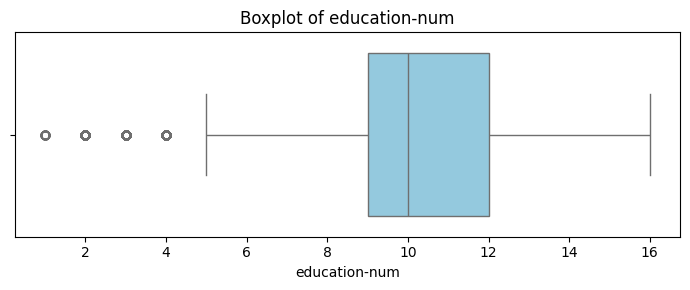

In [5]:
# هر مقدار بیرون از بازهٔ [Q1−1.5×IQR, Q3+1.5×IQR] پرت شمرده می‌شود.
col = "education-num"
x = df[col].dropna()
q1, q3 = x.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = x[(x < lo) | (x > hi)]
print(f"Q1={q1:g}, Q3={q3:g}, IQR={iqr:g}; حدود=[{lo:g}, {hi:g}]")
print(f"تعداد پرت: {len(outliers):,} از {len(x):,} ({len(outliers)/len(x)*100:.2f}٪)")
plt.figure(figsize=(7, 3))
sns.boxplot(x=x, color="skyblue")
plt.title("Boxplot of education-num")
plt.xlabel("education-num")
plt.tight_layout()
plt.show()


## ۳) نمودار Q–Q سن در دو گروه درآمدی
هر نمودار توزیع سن در گروه مربوطه را با توزیع نرمال مقایسه می‌کند.


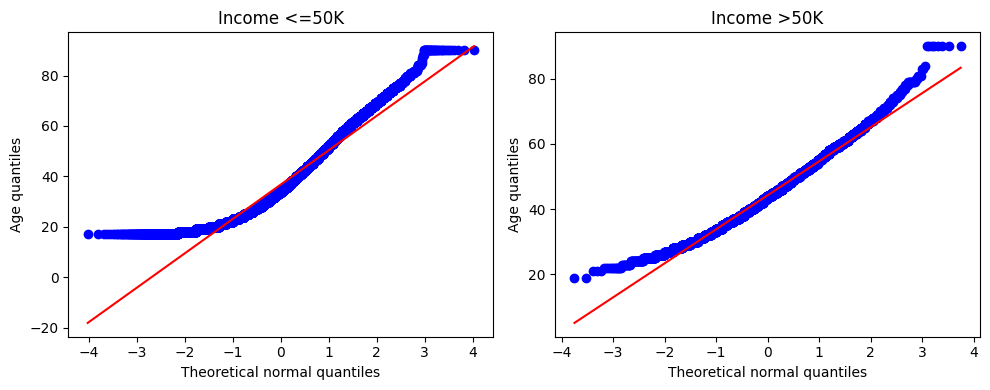

In [6]:
# برچسب درآمد و سن را پاک‌سازی‌شده و بدون مقدار ناموجود انتخاب می‌کنیم.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, label, title in zip(axes, ["<=50K", ">50K"], ["Income <=50K", "Income >50K"]):
    ages = df.loc[df["income"] == label, "age"].dropna()
    stats.probplot(ages, dist="norm", plot=ax)
    ax.set_title(title)
    ax.set_xlabel("Theoretical normal quantiles")
    ax.set_ylabel("Age quantiles")
plt.tight_layout()
plt.show()


## ۴) فاصلهٔ اقلیدسی و منهتن برای ردیف‌های ۲۷ و ۸۱
محاسبه روی `age`، `hoursPerWeek` و `education-num` انجام می‌شود. استانداردسازی Z با میانگین و انحراف معیار کل داده انجام شده است.


In [7]:
# iloc به‌صراحت ردیف‌های با اندیس صفرمبنای ۲۷ و ۸۱ را برمی‌گزیند.
features = ["age", "hoursPerWeek", "education-num"]
points = df[features].astype(float)
a, b = points.iloc[27].to_numpy(), points.iloc[81].to_numpy()
raw = (euclidean(a, b), cityblock(a, b))
scaled = (points - points.mean()) / points.std(ddof=1)
za, zb = scaled.iloc[27].to_numpy(), scaled.iloc[81].to_numpy()
zscore = (euclidean(za, zb), cityblock(za, zb))
print(f"ردیف ۲۷: {a}; ردیف ۸۱: {b}")
print(f"خام — اقلیدسی: {raw[0]:.4f} | منهتن: {raw[1]:.4f}")
print(f"Z-score — اقلیدسی: {zscore[0]:.4f} | منهتن: {zscore[1]:.4f}")


ردیف ۲۷: [54. 60. 10.]; ردیف ۸۱: [52. 40. 13.]
خام — اقلیدسی: 20.3224 | منهتن: 25.0000
Z-score — اقلیدسی: 2.0012 | منهتن: 2.9325


## ۵) عدم‌شباهت اسمی برای ردیف‌های ۲ و ۴
عدم‌شباهت برابر نسبت ویژگی‌های نامتطابق از `occupation`، `marital-status` و `workclass` است.


In [8]:
# مقایسهٔ اسمی: تطابق=۰ و عدم‌تطابق=۱؛ مقدار ناموجود نیز جداگانه بررسی می‌شود.
cat_cols = ["occupation", "marital-status", "workclass"]
p2 = df.iloc[2][cat_cols]
p4 = df.iloc[4][cat_cols]
valid = p2.notna() & p4.notna()
if not valid.any():
    raise ValueError("هیچ ویژگی اسمی مشترکِ غیرخالی برای مقایسه وجود ندارد.")
dissimilarity = (p2[valid].to_numpy() != p4[valid].to_numpy()).mean()
print("ردیف ۲:\n", p2.to_string(), "\nردیف ۴:\n", p4.to_string(), sep="")
print(f"ویژگی‌های قابل مقایسه: {valid.sum()}/{len(cat_cols)}؛ عدم‌شباهت: {dissimilarity:.4f} ({dissimilarity*100:.1f}٪)")


ردیف ۲:
occupation        Handlers-cleaners
marital-status             Divorced
workclass                   Private
ردیف ۴:
occupation            Prof-specialty
marital-status    Married-civ-spouse
workclass                    Private
ویژگی‌های قابل مقایسه: 3/3؛ عدم‌شباهت: 0.6667 (66.7٪)


## ۶) شباهت کسینوسی ردیف‌های ۳۲ و ۶۴ (`age`, `education-num`)


ردیف ۳۲: [45. 13.]; ردیف ۶۴: [29. 10.]
شباهت کسینوسی: 0.99871


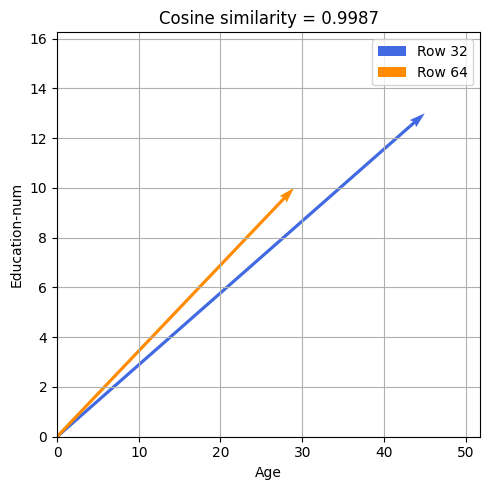

In [9]:
# شباهت کسینوسی = ضرب داخلی تقسیم بر حاصل‌ضرب اندازهٔ دو بردار.
vec_cols = ["age", "education-num"]
v32 = df.iloc[32][vec_cols].to_numpy(dtype=float)
v64 = df.iloc[64][vec_cols].to_numpy(dtype=float)
norm_product = np.linalg.norm(v32) * np.linalg.norm(v64)
cos_sim = np.dot(v32, v64) / norm_product if norm_product else np.nan
print(f"ردیف ۳۲: {v32}; ردیف ۶۴: {v64}")
print(f"شباهت کسینوسی: {cos_sim:.5f}")
plt.figure(figsize=(5, 5))
plt.quiver(0, 0, *v32, angles="xy", scale_units="xy", scale=1, color="royalblue", label="Row 32")
plt.quiver(0, 0, *v64, angles="xy", scale_units="xy", scale=1, color="darkorange", label="Row 64")
plt.xlim(0, max(v32[0], v64[0]) * 1.15)
plt.ylim(0, max(v32[1], v64[1]) * 1.25)
plt.xlabel("Age")
plt.ylabel("Education-num")
plt.title(f"Cosine similarity = {cos_sim:.4f}")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


## ۷) عدم‌شباهت Gower برای ردیف‌های ۵ و ۱۲۵
ترکیب `age` و `education-num` عددی (اختلاف مطلق تقسیم بر دامنه)، `sex` دودویی و `marital-status` اسمی است. میانگین فقط بر ویژگی‌های معتبر محاسبه می‌شود.


In [10]:
# Gower برای دادهٔ عددی دامنه‌مقیاس و برای دسته‌ای تطابق/عدم‌تطابق می‌سنجد.
ra, rb = df.iloc[5], df.iloc[125]
parts = {}
for col in ["age", "education-num"]:
    span = df[col].max() - df[col].min()
    parts[col] = abs(float(ra[col]) - float(rb[col])) / span if span else np.nan
for col in ["sex", "marital-status"]:
    parts[col] = float(ra[col] != rb[col]) if pd.notna(ra[col]) and pd.notna(rb[col]) else np.nan
gower = float(np.nanmean(list(parts.values())))
print("اجزای عدم‌شباهت:", {k: round(v, 4) for k, v in parts.items()})
print(f"Gower dissimilarity: {gower:.4f}")


اجزای عدم‌شباهت: {'age': 0.137, 'education-num': 0.0667, 'sex': 0.0, 'marital-status': 0.0}
Gower dissimilarity: 0.0509


## ۸) همبستگی پیرسون سن و ساعت کار هفتگی


In [11]:
# آزمون روی ردیف‌هایی انجام می‌شود که هر دو متغیر معتبر دارند.
pair = df[["age", "hoursPerWeek"]].dropna()
r, p_value = stats.pearsonr(pair["age"], pair["hoursPerWeek"])
print(f"Pearson r={r:.4f}, p-value={p_value:.4g}, n={len(pair):,}")


Pearson r=0.0688, p-value=2.011e-35, n=32,561


## ۹) جدول توافقی و آزمون کای‌دو: جنسیت × تحصیلات
فرض صفر آزمون، استقلال جنسیت و سطح تحصیلات است.


In [12]:
# جدول فراوانی با جمع کل و آزمون استقلال روی جدول بدون حاشیهٔ جمع اجرا می‌شود.
ct = pd.crosstab(df["education"], df["sex"], margins=True, margins_name="مجموع")
display(ct)
ct_raw = pd.crosstab(df["education"], df["sex"])
chi2, p_chi, dof, expected = stats.chi2_contingency(ct_raw)
critical = stats.chi2.ppf(0.95, dof)
print(f"χ²={chi2:.4f}; df={dof}; مقدار بحرانی (α=0.05)={critical:.4f}; p-value={p_chi:.4g}")
print("نتیجه:", "رد فرض استقلال؛ ارتباط آماری معنادار است." if p_chi < 0.05 else "شواهد کافی برای رد فرض استقلال وجود ندارد.")
print(f"کمترین فراوانی موردانتظار: {expected.min():.2f}")


sex,Female,Male,مجموع
education,,,
10th,295,638,933
11th,432,743,1175
12th,144,289,433
1st-4th,46,122,168
5th-6th,84,249,333
7th-8th,160,486,646
9th,144,370,514
Assoc-acdm,421,646,1067
Assoc-voc,500,882,1382


χ²=297.7150; df=15; مقدار بحرانی (α=0.05)=24.9958; p-value=1.668e-54
نتیجه: رد فرض استقلال؛ ارتباط آماری معنادار است.
کمترین فراوانی موردانتظار: 16.87
